# Лабораторная работа № 3. Задание № 1.
> Григорьев Никита M3338, Паховский Иван M3339

## Условие варианта № 1.

$\tau = \mu_1 - \mu_2$; $\sigma_1^2$, $\sigma_2^2$ известны; $\mu_1 = 2$, $\mu_2 = 1$, $\sigma_1^2 = 1$, $\sigma_2^2 = 0.5$

$$
\frac{\overline{X} - \overline{Y} - \tau}{\sigma}, \quad \sigma^2 = \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}.
$$

## Выкладки
$X_1, \dots, X_n \sim \mathcal{N}(\mu_1, \sigma_1^2)$ \
$Y_1, \dots, Y_n \sim \mathcal{N}(\mu_2, \sigma_2^2)$

Мы хотим найти статистики $T(X,Y)_l, T(X,Y)_r$, чтобы $\mathbb{P}(\tau \in [T(X,Y)_l, T(X,Y)_r]) = 1 - \alpha$.

Известно, что для центральной статистики $G(X, \theta)$ (то есть её распределение не зависит от $\theta$),  $\mathbb{P}(q_{\frac{\alpha}{2}} \le G(X, \theta) \le q_{1-\frac{\alpha}{2}}) = 1-\alpha$.

Покажем, что распределение $\frac{\overline{X} - \overline{Y} - \tau}{\sigma}$ не зависит от $\tau$:

$$\frac{\overline{X} - \overline{Y} - \tau}{\sigma} = \frac{(\overline{X} - \mu_1) - (\overline{Y} - \mu_2) }{\sigma}$$

1) $\overline{X} \sim \mathcal{N}(\mu_1, \frac{\sigma_1^2}{n})$
2) $(\overline{X} - \mu_1) \sim \mathcal{N}(0, \frac{\sigma_1^2}{n})$
3) Для $\overline{Y}$ аналогично.
4) $(\overline{X} - \mu_1) - (\overline{Y} - \mu_2) \sim \mathcal{N}(0,\frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m})$
5) $\frac{(\overline{X} - \mu_1) - (\overline{Y} - \mu_2)}{\sigma} \sim \mathcal{N}(0,1)$

Тогда доверительный интервал:

$$\mathbb{P}(q_{\frac{\alpha}{2}} \le \frac{\overline{X} - \overline{Y} - \tau}{\sigma} \le q_{1-\frac{\alpha}{2}}) = 1 -\alpha$$

$$\mathbb{P}(-\sigma q_{1-\frac{\alpha}{2}} + \overline{X} -\overline{Y} \le \tau \le -\sigma q_{\frac{\alpha}{2}} + \overline{X} - \overline{Y}) = 1 -\alpha$$

## Что происходит с увеличением объёма выборки

$\overline{X} \rightarrow \mu_1$, $\overline{Y} \rightarrow \mu_2$ по ЗБЧ.

$\sigma = \sqrt(\frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}) \rightarrow 0$.

Длина интервала уменьшается.

In [1]:
import numpy as np
import scipy.stats

MU1 = 2
MU2 = 1

SIGMA1_2 = 1
SIGMA2_2 = 0.5

ALPHA = 0.05

SAMPLE_SIZES = [10, 100, 1000, 10000, 100000, 1000000]
NUM_SAPLES = 1000

TAU_TEOR = MU1 - MU2

In [2]:
def calc_confidence_interval(X, Y, alpha):
    global SIGMA1_2, SIGMA2_2
    sigma = np.sqrt(SIGMA1_2 / len(X) + SIGMA2_2 / len(Y))

    return (-sigma * scipy.stats.norm.ppf(1 - alpha / 2) + np.mean(X) - np.mean(Y), -sigma * scipy.stats.norm.ppf(alpha / 2) + np.mean(X) - np.mean(Y))

In [3]:
def run(num_samples, one_sample_size_X, one_sample_size_Y, alpha):
    global MU1, MU2, SIGMA1_2, SIGMA2_2, TAU_TEOR

    intervals = []
    good_intervals_count = 0

    for _ in range(num_samples):
        X = np.random.normal(loc=MU1, scale=np.sqrt(SIGMA1_2), size=one_sample_size_X)
        Y = np.random.normal(loc=MU2, scale=np.sqrt(SIGMA2_2), size=one_sample_size_Y)

        tau1, tau2 = calc_confidence_interval(X, Y, alpha)

        if TAU_TEOR >= tau1 and TAU_TEOR <= tau2:
            good_intervals_count += 1

        intervals.append((tau1, tau2))

    return (intervals, good_intervals_count)

N = 10 M = 10
Good intervals: 947
Good intervals proprortion: 0.947
Mean interval: (0.2305068186180981, 1.7486883928760901)
Mean interval len: 1.518181574257992

N = 100 M = 100
Good intervals: 973
Good intervals proprortion: 0.973
Mean interval: (0.7566791126094563, 1.236770280244988)
Mean interval len: 0.4800911676355317

N = 1000 M = 1000
Good intervals: 949
Good intervals proprortion: 0.949
Mean interval: (0.9243234107962972, 1.0761415682220974)
Mean interval len: 0.15181815742580018

N = 10000 M = 10000
Good intervals: 946
Good intervals proprortion: 0.946
Mean interval: (0.9759208342908887, 1.0239299510544406)
Mean interval len: 0.04800911676355191

N = 100000 M = 100000
Good intervals: 943
Good intervals proprortion: 0.943
Mean interval: (0.9923596014213344, 1.0075414171639134)
Mean interval len: 0.015181815742579041

N = 1000000 M = 1000000
Good intervals: 957
Good intervals proprortion: 0.957
Mean interval: (0.997595682796334, 1.0023965944726902)
Mean interval len: 0.004800911

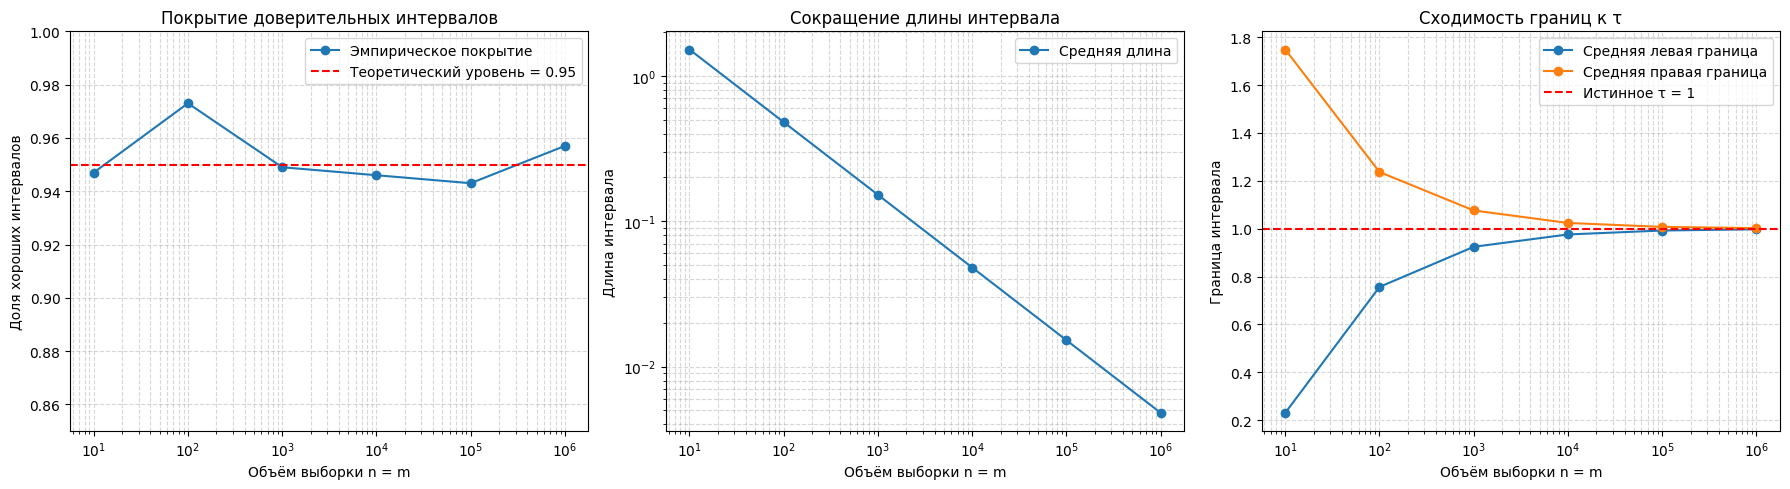

In [5]:
import matplotlib.pyplot as plt

coverages = []
mean_interval_lengths = []
mean_lower_bounds = []
mean_upper_bounds = []

for i in SAMPLE_SIZES:
    intervals, good_intervals = run(NUM_SAPLES, i, i, ALPHA)

    print(f'N = {i} M = {i}')
    print(f'Good intervals: {good_intervals}')
    print(f'Good intervals proprortion: {good_intervals / NUM_SAPLES}')

    firsts, seconds = zip(*intervals)
    result = (sum(firsts) / len(intervals), sum(seconds) / len(intervals))

    print(f'Mean interval: ({result[0]}, {result[1]})')
    print(f'Mean interval len: {result[1] - result[0]}')
    print()

    coverages.append(good_intervals / NUM_SAPLES)
    mean_interval_lengths.append(result[1] - result[0])
    mean_lower_bounds.append(result[0])
    mean_upper_bounds.append(result[1])

z = scipy.stats.norm.ppf(1 - ALPHA / 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(SAMPLE_SIZES, coverages, marker='o', label='Эмпирическое покрытие')
axes[0].axhline(1 - ALPHA, color='red', linestyle='--', label=f'Теоретический уровень = {1 - ALPHA}')
axes[0].set_xscale('log')
axes[0].set_ylim(0.85, 1.0)
axes[0].set_xlabel('Объём выборки n = m')
axes[0].set_ylabel('Доля хороших интервалов')
axes[0].set_title('Покрытие доверительных интервалов')
axes[0].grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].legend()

axes[1].plot(SAMPLE_SIZES, mean_interval_lengths, marker='o', label='Средняя длина')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Объём выборки n = m')
axes[1].set_ylabel('Длина интервала')
axes[1].set_title('Сокращение длины интервала')
axes[1].grid(True, which='both', linestyle='--', alpha=0.5)
axes[1].legend()

axes[2].plot(SAMPLE_SIZES, mean_lower_bounds, marker='o', label='Средняя левая граница')
axes[2].plot(SAMPLE_SIZES, mean_upper_bounds, marker='o', label='Средняя правая граница')
axes[2].axhline(TAU_TEOR, color='red', linestyle='--', label=f'Истинное τ = {TAU_TEOR}')
axes[2].set_xscale('log')
axes[2].set_xlabel('Объём выборки n = m')
axes[2].set_ylabel('Граница интервала')
axes[2].set_title('Сходимость границ к τ')
axes[2].grid(True, which='both', linestyle='--', alpha=0.5)
axes[2].legend()

plt.tight_layout()
plt.show()